### Broken timing formal experiment

In [35]:
import importlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from time import perf_counter

import src.paths as paths
import src.defects as defects
import src.representations as representations
import src.metrics as metrics

importlib.reload(paths)
importlib.reload(defects)
importlib.reload(representations)
importlib.reload(metrics)

from src.paths import get_project_paths
from src.metrics import c2st_paired,mmd_paired_permutation_test,energy_paired_permutation_test,sinkhorn_divergence,sinkhorn_paired_permutation_test,median_pairwise_euclidean_scale

PATHS=get_project_paths()
DATA_DIR=PATHS["processed"]
RESULTS_DIR=PATHS["results"]
WEEK7_RESULTS_DIR=RESULTS_DIR/"week7"
WEEK7_RESULTS_DIR.mkdir(parents=True,exist_ok=True)

In [36]:
BT_REPS=200
BT_N_PAIRS=100
BT_PERMUTATIONS=100
BT_ALPHA=0.05
BT_SEVERITIES=[0.10,0.30,0.60]
BT_TARGET_GAP=-5.0
BT_PLAN_SEED=42
BT_SAMPLE_BASE_SEED=42
BT_TEST_BASE_SEED=10000

In [37]:
campaigns=pd.read_csv(DATA_DIR/"clean_structured_campaigns.csv")
campaigns["timestamp"]=pd.to_datetime(campaigns["timestamp"])

train_ids=pd.read_csv(DATA_DIR/"clean_structural_train_scaled.csv")["campaign_id"].astype(str).to_numpy()
eval_ids=pd.read_csv(DATA_DIR/"clean_structural_eval_scaled.csv")["campaign_id"].astype(str).to_numpy()

print("Campaigns:",campaigns["campaign_id"].nunique())
print("Messages:",len(campaigns))
print("Reference:",len(train_ids))
print("Evaluation:",len(eval_ids))
print("Overlap:",len(set(train_ids)&set(eval_ids)))

Campaigns: 1000
Messages: 6949
Reference: 700
Evaluation: 300
Overlap: 0


In [38]:
importlib.reload(representations)
from src.representations import structural_campaign_summary

clean_summary_new=structural_campaign_summary(campaigns).sort_values("campaign_id").reset_index(drop=True)
clean_summary_old=pd.read_csv(DATA_DIR/"clean_structural_summary.csv").sort_values("campaign_id").reset_index(drop=True)

FEATURES=[c for c in clean_summary_old.columns if c!="campaign_id"]

print("Same IDs:",np.array_equal(clean_summary_new["campaign_id"],clean_summary_old["campaign_id"]))
print("Max feature difference:",np.max(np.abs(clean_summary_new[FEATURES].to_numpy()-clean_summary_old[FEATURES].to_numpy())))

Same IDs: True
Max feature difference: 1.4210854715202004e-14


In [5]:
# reload and isolate evaluation campaigns
importlib.reload(defects)
from src.defects import make_broken_timing_plan,apply_broken_timing_plan

eval_campaigns=campaigns.loc[campaigns["campaign_id"].isin(eval_ids)].copy()
train_campaigns=campaigns.loc[campaigns["campaign_id"].isin(train_ids)].copy()

print("Reference campaigns:",train_campaigns["campaign_id"].nunique())
print("Evaluation campaigns:",eval_campaigns["campaign_id"].nunique())

Reference campaigns: 700
Evaluation campaigns: 300


In [6]:
# fixed nested plan
bt_plan=make_broken_timing_plan(eval_campaigns,severities=BT_SEVERITIES,target_gap_minutes=BT_TARGET_GAP,seed=BT_PLAN_SEED)

print(bt_plan.groupby("severity").size())
display(bt_plan.head())

severity
0.1     30
0.3     90
0.6    180
dtype: int64


,severity,campaign_id,target_message_order,original_gap_minutes,target_gap_minutes
0,0.1,C0894,7,73.0,-5.0
1,0.1,C0986,6,14.0,-5.0
2,0.1,C0216,2,39.0,-5.0
3,0.1,C0866,7,90.0,-5.0
4,0.1,C0545,2,81.0,-5.0


In [7]:
# validate nesting 
bt_affected={s:set(bt_plan.loc[np.isclose(bt_plan["severity"],s),"campaign_id"]) for s in BT_SEVERITIES}

for s in BT_SEVERITIES: print(f"{s:.0%} | affected =",len(bt_affected[s]))

assert bt_affected[0.10].issubset(bt_affected[0.30])
assert bt_affected[0.30].issubset(bt_affected[0.60])

print("Nested plan passed.")

10% | affected = 30
30% | affected = 90
60% | affected = 180
Nested plan passed.


In [8]:
# build defective conditions
bt_conditions={"clean":eval_campaigns.copy()}

for s in BT_SEVERITIES:
    bt_conditions[s]=apply_broken_timing_plan(eval_campaigns,bt_plan,s)
    print(f"{s:.0%} | rows =",len(bt_conditions[s]))

10% | rows = 2090
30% | rows = 2090
60% | rows = 2090


In [9]:
# verify target gap is -5
def target_gap_check(df,plan,severity):
    p=plan.loc[np.isclose(plan["severity"],severity)]
    rows=[]
    for r in p.itertuples(index=False):
        g=df.loc[df["campaign_id"]==r.campaign_id].sort_values("message_order")
        t=pd.to_datetime(g.loc[g["message_order"]==r.target_message_order,"timestamp"].iloc[0])
        prev=pd.to_datetime(g.loc[g["message_order"]==r.target_message_order-1,"timestamp"].iloc[0])
        rows.append((t-prev).total_seconds()/60)
    return np.asarray(rows)

for s in BT_SEVERITIES:
    gaps=target_gap_check(bt_conditions[s],bt_plan,s)
    print(f"{s:.0%} | n={len(gaps)} | min={gaps.min():.1f} | max={gaps.max():.1f} | mean={gaps.mean():.1f}")
    assert np.allclose(gaps,BT_TARGET_GAP)

10% | n=30 | min=-5.0 | max=-5.0 | mean=-5.0
30% | n=90 | min=-5.0 | max=-5.0 | mean=-5.0
60% | n=180 | min=-5.0 | max=-5.0 | mean=-5.0


In [10]:
# verify unaffected campaigns are identical
for s in BT_SEVERITIES:
    unaffected=set(eval_ids)-bt_affected[s]
    a=eval_campaigns.loc[eval_campaigns["campaign_id"].isin(unaffected)].sort_values(["campaign_id","message_order"]).reset_index(drop=True)
    b=bt_conditions[s].loc[bt_conditions[s]["campaign_id"].isin(unaffected)].sort_values(["campaign_id","message_order"]).reset_index(drop=True)
    print(f"{s:.0%} | unaffected identical:",a.equals(b))

10% | unaffected identical: True
30% | unaffected identical: True
60% | unaffected identical: True


In [11]:
# verify non temporal fields are unchanged everywhere 
NON_TEMP=[c for c in eval_campaigns.columns if c!="timestamp"]

for s in BT_SEVERITIES:
    a=eval_campaigns.sort_values(["campaign_id","message_order"]).reset_index(drop=True)
    b=bt_conditions[s].sort_values(["campaign_id","message_order"]).reset_index(drop=True)
    print(f"{s:.0%} | non-temporal preserved:",a[NON_TEMP].equals(b[NON_TEMP]))

10% | non-temporal preserved: True
30% | non-temporal preserved: True
60% | non-temporal preserved: True


In [12]:
# build structural summaries 
bt_raw={"clean":structural_campaign_summary(bt_conditions["clean"])}

for s in BT_SEVERITIES:
    bt_raw[s]=structural_campaign_summary(bt_conditions[s])
    print(f"{s:.0%}:",bt_raw[s].shape)

print("Clean:",bt_raw["clean"].shape)

10%: (300, 14)
30%: (300, 14)
60%: (300, 14)
Clean: (300, 14)


In [13]:
# align summaries by the same evaluation id 
def align_summary(df,ids):
    return df.set_index("campaign_id").loc[ids].reset_index()

bt_raw={k:align_summary(v,eval_ids) for k,v in bt_raw.items()}

for k,v in bt_raw.items():
    assert np.array_equal(v["campaign_id"].to_numpy(),eval_ids)

print("Summary alignment passed.")

Summary alignment passed.


In [14]:
# verify non emporal structural features
TEMP_FEATURES=["campaign_duration","mean_time_gap","median_time_gap","std_time_gap"]
NON_TEMP_FEATURES=[c for c in FEATURES if c not in TEMP_FEATURES]

for s in BT_SEVERITIES:
    diff=np.abs(bt_raw[s][NON_TEMP_FEATURES].to_numpy()-bt_raw["clean"][NON_TEMP_FEATURES].to_numpy())
    print(f"{s:.0%} | max non-temporal feature change =",diff.max())

10% | max non-temporal feature change = 0.0
30% | max non-temporal feature change = 0.0
60% | max non-temporal feature change = 0.0


In [15]:
# fit scaler on clean reference only
train_summary=structural_campaign_summary(train_campaigns).set_index("campaign_id").loc[train_ids].reset_index()

scaler=StandardScaler()
X_bt_train=scaler.fit_transform(train_summary[FEATURES]).astype(np.float32)

X_bt={}
for k,df in bt_raw.items(): X_bt[k]=scaler.transform(df[FEATURES]).astype(np.float32)

print("Reference:",X_bt_train.shape)
for k,X in X_bt.items(): print(k,X.shape)

Reference: (700, 13)
clean (300, 13)
0.1 (300, 13)
0.3 (300, 13)
0.6 (300, 13)


In [16]:
# validate clean scaling agains frozen artifact 
saved_eval=pd.read_csv(DATA_DIR/"clean_structural_eval_scaled.csv").set_index("campaign_id").loc[eval_ids]
print("Max clean scaled difference:",np.max(np.abs(X_bt["clean"]-saved_eval[FEATURES].to_numpy())))

Max clean scaled difference: 1.3729358627756483e-07


In [17]:
bt_plan.to_csv(DATA_DIR/"broken_timing_formal_plan.csv",index=False)

for k,df in bt_raw.items():
    name="clean" if k=="clean" else f"{int(k*100)}pct"
    df.to_csv(DATA_DIR/f"broken_timing_structural_{name}.csv",index=False)

print("Broken Timing formal artifacts saved.")

Broken Timing formal artifacts saved.


In [18]:
# clean deriveed md sigma and sinkhorn blur
BT_CLEAN_SCALE=median_pairwise_euclidean_scale(X_bt_train)
BT_MMD_SIGMA=BT_CLEAN_SCALE
BT_SINKHORN_BLUR=0.10*BT_CLEAN_SCALE

print("Median clean structural distance:",BT_CLEAN_SCALE)
print("Frozen MMD sigma:",BT_MMD_SIGMA)
print("Frozen Sinkhorn blur:",BT_SINKHORN_BLUR)

Median clean structural distance: 4.82953793971741
Frozen MMD sigma: 4.82953793971741
Frozen Sinkhorn blur: 0.482953793971741


In [19]:
# sinkhorn identity check
identity=sinkhorn_divergence(X_bt["clean"][:100],X_bt["clean"][:100],blur=BT_SINKHORN_BLUR)
print("S(X,X):",f"{identity:.12e}")

S(X,X): 0.000000000000e+00


In [ ]:
# compact metric helper 
def metric_record(metric,result,runtime):
    stat=result.get("statistic",result.get("accuracy"))
    reject=result.get("reject",result.get("reject_H0"))
    row={"metric":metric,"statistic":float(stat),"p_value":float(result["p_value"]),"reject":bool(reject),"runtime_seconds":runtime}
    if "null_mean" in result: row["null_mean"]=float(result["null_mean"])
    if "null_std" in result: row["null_std"]=float(result["null_std"])
    return row

In [21]:
# one function for  metrics 
def run_bt_metrics(P,Q,seed):
    rows=[]
    start=perf_counter(); r=c2st_paired(P,Q,test_size=0.5,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("C2ST",r,perf_counter()-start))
    start=perf_counter(); r=mmd_paired_permutation_test(P,Q,sigma=BT_MMD_SIGMA,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("MMD",r,perf_counter()-start))
    start=perf_counter(); r=energy_paired_permutation_test(P,Q,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("Energy",r,perf_counter()-start))
    start=perf_counter(); r=sinkhorn_paired_permutation_test(P,Q,blur=BT_SINKHORN_BLUR,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("Sinkhorn",r,perf_counter()-start))
    return rows

In [22]:
## formal independent clean vs clean paired nulls 
def run_bt_metrics(P,Q,seed):
    rows=[]
    start=perf_counter(); r=c2st_paired(P,Q,test_size=0.5,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("C2ST",r,perf_counter()-start))
    start=perf_counter(); r=mmd_paired_permutation_test(P,Q,sigma=BT_MMD_SIGMA,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("MMD",r,perf_counter()-start))
    start=perf_counter(); r=energy_paired_permutation_test(P,Q,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("Energy",r,perf_counter()-start))
    start=perf_counter(); r=sinkhorn_paired_permutation_test(P,Q,blur=BT_SINKHORN_BLUR,n_permutations=BT_PERMUTATIONS,seed=seed,alpha=BT_ALPHA); rows.append(metric_record("Sinkhorn",r,perf_counter()-start))
    return rows

In [23]:
# null summary
bt_null_records=[]
start=perf_counter()

for rep in range(BT_REPS):
    rng=np.random.default_rng(42000+rep)
    selected=rng.choice(len(eval_ids),size=2*BT_N_PAIRS,replace=False)
    P=X_bt["clean"][selected[:BT_N_PAIRS]]
    Q=X_bt["clean"][selected[BT_N_PAIRS:]]
    for row in run_bt_metrics(P,Q,BT_TEST_BASE_SEED+rep): bt_null_records.append({"repetition":rep,**row})
    if (rep+1)%20==0: print(f"Completed {rep+1}/{BT_REPS}")

bt_null_runtime=perf_counter()-start
bt_null_runs=pd.DataFrame(bt_null_records)

print("Runtime:",round(bt_null_runtime/60,2),"minutes")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 7.05 minutes


In [24]:
bt_null_summary=bt_null_runs.groupby("metric").agg(repetitions=("reject","size"),rejections=("reject","sum"),type_I_error=("reject","mean"),mean_p_value=("p_value","mean"),median_p_value=("p_value","median"),mean_statistic=("statistic","mean"),std_statistic=("statistic","std"),mean_runtime_seconds=("runtime_seconds","mean")).reset_index()
display(bt_null_summary)

,metric,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_runtime_seconds
0,C2ST,200,7,0.035,0.569010,0.569307,0.499350,0.049246,0.023657
1,Energy,200,13,0.065,0.510248,0.500000,0.000421,0.032237,0.052166
2,MMD,200,11,0.055,0.513069,0.504950,0.000040,0.003766,0.054921
3,Sinkhorn,200,9,0.045,0.519554,0.514851,2.933983,0.157746,1.983344


In [25]:
bt_null_runs.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_null_runs.csv",index=False)
bt_null_summary.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_null_summary.csv",index=False)

In [26]:
# full experiment
bt_power_records=[]
start=perf_counter()

for rep in range(BT_REPS):
    rng=np.random.default_rng(BT_SAMPLE_BASE_SEED+rep)
    idx=rng.choice(len(eval_ids),size=BT_N_PAIRS,replace=False)
    sampled_ids=eval_ids[idx]
    P=X_bt["clean"][idx]

    for severity in BT_SEVERITIES:
        Q=X_bt[severity][idx]
        n_affected=sum(cid in bt_affected[severity] for cid in sampled_ids)
        for row in run_bt_metrics(P,Q,BT_TEST_BASE_SEED+rep): bt_power_records.append({"repetition":rep,"severity":severity,"n_pairs":BT_N_PAIRS,"n_affected":n_affected,"sample_affected_rate":n_affected/BT_N_PAIRS,**row})

    if (rep+1)%20==0: print(f"Completed {rep+1}/{BT_REPS} | elapsed {round((perf_counter()-start)/60,1)} min")

bt_power_runtime=perf_counter()-start
bt_power_runs=pd.DataFrame(bt_power_records)

print("Rows:",len(bt_power_runs))
print("Expected:",BT_REPS*len(BT_SEVERITIES)*4)
print("Runtime:",round(bt_power_runtime/60,2),"minutes")

Completed 20/200 | elapsed 2.5 min
Completed 40/200 | elapsed 4.1 min
Completed 60/200 | elapsed 5.5 min
Completed 80/200 | elapsed 6.7 min
Completed 100/200 | elapsed 7.9 min
Completed 120/200 | elapsed 9.3 min
Completed 140/200 | elapsed 10.4 min
Completed 160/200 | elapsed 11.6 min
Completed 180/200 | elapsed 12.7 min
Completed 200/200 | elapsed 13.8 min
Rows: 2400
Expected: 2400
Runtime: 13.84 minutes


In [27]:
# effective prevalence 
bt_prevalence_check=bt_power_runs.drop_duplicates(["repetition","severity"]).groupby("severity").agg(mean_affected=("n_affected","mean"),std_affected=("n_affected","std"),min_affected=("n_affected","min"),max_affected=("n_affected","max"),mean_sample_rate=("sample_affected_rate","mean")).reset_index()
display(bt_prevalence_check)

,severity,mean_affected,std_affected,min_affected,max_affected,mean_sample_rate
0,0.1,10.190,2.394277,3,16,0.10190
1,0.3,30.180,3.899182,19,41,0.30180
2,0.6,60.245,4.220669,50,72,0.60245


In [28]:
# power summary
bt_power_summary=bt_power_runs.groupby(["severity","metric"]).agg(repetitions=("reject","size"),rejections=("reject","sum"),power=("reject","mean"),mean_p_value=("p_value","mean"),median_p_value=("p_value","median"),mean_statistic=("statistic","mean"),std_statistic=("statistic","std"),mean_runtime_seconds=("runtime_seconds","mean"),mean_affected=("n_affected","mean"),mean_sample_affected_rate=("sample_affected_rate","mean")).reset_index()
display(bt_power_summary)

,severity,metric,repetitions,rejections,power,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_runtime_seconds,mean_affected,mean_sample_affected_rate
0,0.1,C2ST,200,5,0.025,0.402822,0.277228,0.517900,0.012220,0.017188,10.190,0.10190
1,0.1,Energy,200,195,0.975,0.015396,0.009901,-0.092829,0.003360,0.051723,10.190,0.10190
2,0.1,MMD,200,195,0.975,0.016040,0.009901,-0.007672,0.000350,0.050201,10.190,0.10190
3,0.1,Sinkhorn,200,66,0.330,0.331238,0.222772,0.132371,0.039536,1.293051,10.190,0.10190
4,0.3,C2ST,200,167,0.835,0.034752,0.019802,0.569900,0.022595,0.019228,30.180,0.30180
5,0.3,Energy,200,200,1.000,0.009901,0.009901,-0.055051,0.011266,0.052698,30.180,0.30180
6,0.3,MMD,200,200,1.000,0.009901,0.009901,-0.003805,0.001214,0.050529,30.180,0.30180
7,0.3,Sinkhorn,200,188,0.940,0.025792,0.009901,0.465046,0.080208,1.240592,30.180,0.30180
8,0.6,C2ST,200,200,1.000,0.010099,0.009901,0.660950,0.031055,0.018596,60.245,0.60245
9,0.6,Energy,200,200,1.000,0.009901,0.009901,0.057056,0.024751,0.052472,60.245,0.60245


In [29]:
bt_power_table=bt_power_summary.pivot(index="severity",columns="metric",values="power").reset_index()
display(bt_power_table)

metric,severity,C2ST,Energy,MMD,Sinkhorn
0,0.1,0.025,0.975,0.975,0.33
1,0.3,0.835,1.000,1.000,0.94
2,0.6,1.000,1.000,1.000,1.00


In [30]:
# monte carlo intervals
bt_power_summary["mc_se"]=np.sqrt(bt_power_summary["power"]*(1-bt_power_summary["power"])/bt_power_summary["repetitions"])
bt_power_summary["ci95_lower"]=(bt_power_summary["power"]-1.96*bt_power_summary["mc_se"]).clip(0,1)
bt_power_summary["ci95_upper"]=(bt_power_summary["power"]+1.96*bt_power_summary["mc_se"]).clip(0,1)

display(bt_power_summary[["severity","metric","power","mc_se","ci95_lower","ci95_upper"]])

,severity,metric,power,mc_se,ci95_lower,ci95_upper
0,0.1,C2ST,0.025,0.011040,0.003362,0.046638
1,0.1,Energy,0.975,0.011040,0.953362,0.996638
2,0.1,MMD,0.975,0.011040,0.953362,0.996638
3,0.1,Sinkhorn,0.330,0.033249,0.264832,0.395168
4,0.3,C2ST,0.835,0.026246,0.783557,0.886443
5,0.3,Energy,1.000,0.000000,1.000000,1.000000
6,0.3,MMD,1.000,0.000000,1.000000,1.000000
7,0.3,Sinkhorn,0.940,0.016793,0.907086,0.972914
8,0.6,C2ST,1.000,0.000000,1.000000,1.000000
9,0.6,Energy,1.000,0.000000,1.000000,1.000000


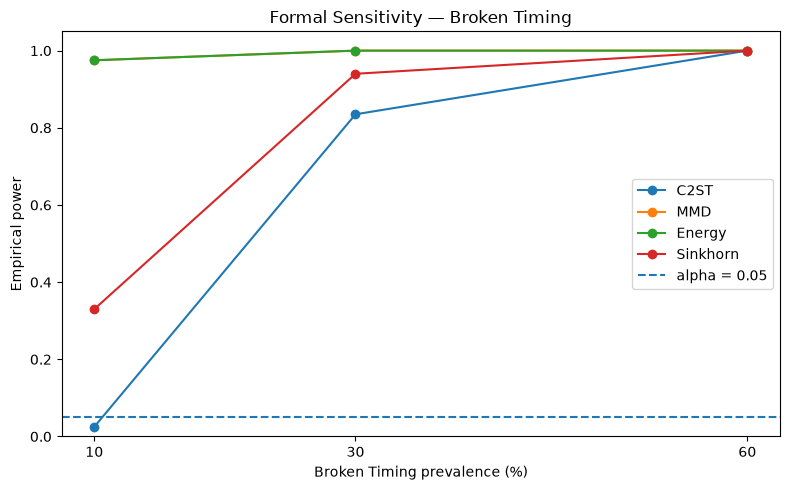

In [31]:
plt.figure(figsize=(8,5))

for metric in ["C2ST","MMD","Energy","Sinkhorn"]:
    d=bt_power_summary.loc[bt_power_summary["metric"]==metric].sort_values("severity")
    plt.plot(d["severity"]*100,d["power"],marker="o",label=metric)

plt.axhline(BT_ALPHA,linestyle="--",label="alpha = 0.05")
plt.xlabel("Broken Timing prevalence (%)")
plt.ylabel("Empirical power")
plt.title("Formal Sensitivity — Broken Timing")
plt.xticks([10,30,60])
plt.ylim(0,1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
# inspect representation response
bt_rep_response=[]

for s in BT_SEVERITIES:
    D=np.linalg.norm(X_bt[s]-X_bt["clean"],axis=1)
    mask=np.array([cid in bt_affected[s] for cid in eval_ids])
    bt_rep_response.append({"severity":s,"n_affected":mask.sum(),"mean_affected_distance":D[mask].mean(),"std_affected_distance":D[mask].std(),"median_affected_distance":np.median(D[mask]),"mean_unaffected_distance":D[~mask].mean(),"max_unaffected_distance":D[~mask].max()})

bt_rep_response=pd.DataFrame(bt_rep_response)
display(bt_rep_response)

,severity,n_affected,mean_affected_distance,std_affected_distance,median_affected_distance,mean_unaffected_distance,max_unaffected_distance
0,0.1,30,1.507846,0.595199,1.463477,0.0,0.0
1,0.3,90,1.614294,0.742963,1.561982,0.0,0.0
2,0.6,180,1.624370,0.712970,1.585907,0.0,0.0


In [33]:
bt_power_runs.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_power_runs.csv",index=False)
bt_power_summary.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_power_summary.csv",index=False)
bt_power_table.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_power_table.csv",index=False)
bt_prevalence_check.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_sample_prevalence.csv",index=False)
bt_rep_response.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_representation_response.csv",index=False)

print("Formal Broken Timing results saved.")

Formal Broken Timing results saved.


In [34]:
bt_config={"defect":"Broken Timing","experimental_unit":"campaign","representation":"13-feature generic structural summary","fixed_target_gap_minutes":BT_TARGET_GAP,"severity_definition":"prevalence of affected campaigns","nested_prevalence":True,"severities":BT_SEVERITIES,"repetitions":BT_REPS,"pairs_per_repetition":BT_N_PAIRS,"permutations":BT_PERMUTATIONS,"alpha":BT_ALPHA,"mmd_sigma":BT_MMD_SIGMA,"sinkhorn_blur":BT_SINKHORN_BLUR,"clean_geometric_scale":BT_CLEAN_SCALE,"scaler_fit":"700 clean reference campaigns only","plan_seed":BT_PLAN_SEED,"sampling_seed_base":BT_SAMPLE_BASE_SEED,"test_seed_base":BT_TEST_BASE_SEED}

with open(WEEK7_RESULTS_DIR/"broken_timing_formal_configuration.json","w") as f: json.dump(bt_config,f,indent=4)

print("Configuration saved.")

Configuration saved.


### Formal Broken Timing experiment summary

The original Broken Timing pilot varied temporal violation magnitude ($-1$, $-5$, $-15$ minutes), resulting in complete power saturation ($1.000$) across all metrics. To generate a realistic sensitivity curve, the formal experiment shifted the definition of severity from **defect magnitude** to **defect prevalence**:
* Defect fixed strictly at **$-5\text{ minutes}$** for a single target message per affected campaign.
* **Severity Levels (Prevalence):** $10\%$ (30 campaigns), $30\%$ (90 campaigns), and $60\%$ (180 campaigns) using nested affected sets ($A_{10\%} \subset A_{30\%} \subset A_{60\%}$).
* **Dataset Split:** 1,000 structured campaigns (6,949 messages split into 700 clean reference / 300 clean evaluation).



#### Validation and null calibration
* Non-temporal fields, message orders, metadata, and unaffected campaigns remained perfectly preserved (`True`). Unaffected campaign displacement in representation space was exactly $0.0$.
* Summary vectors built from 13 generic structural features (durations, time gaps, channels, message lengths) were standardized strictly using the clean reference set.
* **Null Calibration ($\alpha = 0.05$, 200 Repetitions):** Tested on independent clean evaluation draws, confirming well-calibrated Type I error rates:
  * **C2ST:** $0.035$ (Mean $p$: $0.569$)
  * **Energy Distance:** $0.065$ (Mean $p$: $0.510$)
  * **MMD:** $0.055$ (Mean $p$: $0.513$)
  * **Sinkhorn Divergence:** $0.045$ (Mean $p$: $0.520$)


#### Empirical power 

| Prevalence | C2ST | Energy Distance | MMD | Sinkhorn Divergence |
| :--- | :---: | :---: | :---: | :---: |
| **10%** | $0.025$ | $0.975$ | $0.975$ | $0.330$ |
| **30%** | $0.835$ | $1.000$ | $1.000$ | $0.940$ |
| **60%** | $1.000$ | $1.000$ | $1.000$ | $1.000$ |



#### Key insights and diagnostic behavior

1. **MMD and Energy Distance are Dominant:**
   * Both metrics reach **$0.975$ power at just $10\%$ prevalence**, proving that non-parametric kernel/distance metrics effectively register population-level variance changes without hand-crafted features like `negative_gap_count`.

2. **C2ST Struggles at Low Prevalence:**
   * At $10\%$ prevalence, linear C2ST power falls to **$0.025$** (equivalent to null behavior). The linear logistic classifier fails to find a distinct decision boundary when defect signals are diluted across sample pairs.

3. **Sinkhorn Dynamics and Computational Trade-off:**
   * Sinkhorn exhibits intermediate power scaling ($0.330 \rightarrow 0.940 \rightarrow 1.000$). However, it incurs a substantial runtime penalty (~$1.25\text{s}$ per test vs. ~$0.05\text{s}$ for MMD/Energy and ~$0.02\text{s}$ for C2ST).


**Conclusion:**
   $$\text{Representation Response} \neq \text{Metric Sensitivity}$$
   While affected campaigns undergo measurable structural displacement ($\approx 1.51 - 1.62$ distance units), statistical detection strictly depends on how each metric family evaluates structural geometry.

In [39]:
# recovery verification
print(X_bt["clean"].shape)
print(BT_SINKHORN_BLUR)
print(len(eval_ids))
print({s:len(bt_affected[s]) for s in BT_SEVERITIES})

(300, 13)
0.482953793971741
300
{0.1: 30, 0.3: 90, 0.6: 180}


In [40]:
# recovery loop 
bt_sinkhorn_recovery=[]
start=perf_counter()

for rep in range(BT_REPS):
    rng=np.random.default_rng(BT_SAMPLE_BASE_SEED+rep)
    idx=rng.choice(len(eval_ids),size=BT_N_PAIRS,replace=False)
    sampled_ids=eval_ids[idx]
    P=X_bt["clean"][idx]

    for severity in BT_SEVERITIES:
        Q=X_bt[severity][idx]
        n_affected=sum(cid in bt_affected[severity] for cid in sampled_ids)

        t0=perf_counter()
        r=sinkhorn_paired_permutation_test(P,Q,blur=BT_SINKHORN_BLUR,n_permutations=BT_PERMUTATIONS,seed=BT_TEST_BASE_SEED+rep,alpha=BT_ALPHA)

        bt_sinkhorn_recovery.append({
            "repetition":rep,"severity":severity,"n_pairs":BT_N_PAIRS,
            "n_affected":n_affected,"sample_affected_rate":n_affected/BT_N_PAIRS,
            "statistic":r["statistic"],"p_value":r["p_value"],"reject":r["reject"],
            "null_mean":r["null_mean"],"null_std":r["null_std"],
            "runtime_seconds":perf_counter()-t0
        })

    if (rep+1)%20==0: print(f"Completed {rep+1}/{BT_REPS}")

bt_sinkhorn_recovery=pd.DataFrame(bt_sinkhorn_recovery)

print("Rows:",len(bt_sinkhorn_recovery),"Expected:",600)
print("Runtime:",round((perf_counter()-start)/60,2),"minutes")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Rows: 600 Expected: 600
Runtime: 14.53 minutes


In [41]:
# verify againsta og run
bt_old=pd.read_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_power_runs.csv")
bt_old_sink=bt_old.loc[bt_old["metric"]=="Sinkhorn"].copy()

bt_check=bt_old_sink.merge(bt_sinkhorn_recovery,on=["repetition","severity"],suffixes=("_old","_new"))

bt_check["stat_diff"]=np.abs(bt_check["statistic_old"]-bt_check["statistic_new"])
bt_check["p_diff"]=np.abs(bt_check["p_value_old"]-bt_check["p_value_new"])
bt_check["reject_same"]=bt_check["reject_old"]==bt_check["reject_new"]

print("Rows compared:",len(bt_check))
print("Max statistic difference:",bt_check["stat_diff"].max())
print("Max p-value difference:",bt_check["p_diff"].max())
print("Same reject decisions:",bt_check["reject_same"].all())

Rows compared: 600
Max statistic difference: 2.220446049250313e-16
Max p-value difference: 1.1102230246251565e-16
Same reject decisions: True


In [42]:
# observed minus null 
bt_sinkhorn_recovery["obs_minus_null"]=bt_sinkhorn_recovery["statistic"]-bt_sinkhorn_recovery["null_mean"]

bt_sinkhorn_gap=bt_sinkhorn_recovery.groupby("severity").agg(
    mean_statistic=("statistic","mean"),
    mean_null=("null_mean","mean"),
    mean_obs_minus_null=("obs_minus_null","mean"),
    std_obs_minus_null=("obs_minus_null","std"),
    power=("reject","mean")
).reset_index()

display(bt_sinkhorn_gap)

,severity,mean_statistic,mean_null,mean_obs_minus_null,std_obs_minus_null,power
0,0.1,0.132371,0.132156,0.000215,0.000499,0.33
1,0.3,0.465046,0.445885,0.019161,0.014299,0.94
2,0.6,0.937028,0.868656,0.068373,0.027331,1.00


In [43]:
bt_sinkhorn_recovery.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_sinkhorn_power_runs_enriched.csv",index=False)
bt_sinkhorn_gap.to_csv(WEEK7_RESULTS_DIR/"broken_timing_formal_sinkhorn_null_gap.csv",index=False)